In [10]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs("data", exist_ok=True)
plt.rcParams["figure.figsize"] = (9, 4)

In [11]:
games = pd.read_csv("data/games.csv")
stats = pd.read_csv("data/stats.csv")
players = pd.read_csv("data/players.csv")

games["Date"] = pd.to_datetime(games["Date"])
games["Attendance"] = pd.to_numeric(
    games["Attendance"].astype(str).str.replace(",", "", regex=False), errors="coerce")
for col in ["MaxTemp", "MinTemp", "Rainfall"]:
    games[col] = games[col].fillna(games[col].median())

# quarter scores are ambiguous (goals.behinds as decimals) and would leak the result
games = games.drop(columns=[c for c in games.columns if any(k in c for k in ("QT", "HT", "FT"))])

games["Margin"] = games["HomeTeamScore"] - games["AwayTeamScore"]
games["HomeWin"] = (games["Margin"] > 0).astype(int)
games["IsFinal"] = games["Round"].str.contains("Final").astype(int)
games["RoundNum"] = pd.to_numeric(games["Round"].str.extract(r"(\d+)")[0], errors="coerce")
games.loc[games["Round"] == "Opening Round", "RoundNum"] = 0

rare = games["Venue"].value_counts()
rare = rare[rare < 30].index
games["VenueGroup"] = games["Venue"].where(~games["Venue"].isin(rare), "Other")

# GameId is unreliable in 2024, so use our own unique key
games = games.sort_values(["Date", "HomeTeam"]).reset_index(drop=True)
games["GameKey"] = games.index
games.shape

(2879, 20)

In [12]:
stats = stats.rename(columns={"%Played": "PctPlayed"}).drop(columns=["Subs"])

# rebuild each team's score from player goals/behinds
sg = (stats.groupby(["GameId", "Team"], as_index=False)
      .agg(Year=("Year", "first"), G=("Goals", "sum"), B=("Behinds", "sum")))
sg["Pts"] = 6 * sg["G"] + sg["B"]

lookup = {}
for r in games.itertuples():
    lookup.setdefault((r.Year, frozenset([r.HomeTeam, r.AwayTeam])), []).append(r)

matches, skipped = [], []
for gid, d in sg.groupby("GameId"):
    if len(d) != 2:
        skipped.append(gid); continue
    pts = dict(zip(d["Team"], d["Pts"]))
    best = None
    for r in lookup.get((d["Year"].iloc[0], frozenset(pts)), []):
        diff = abs(pts[r.HomeTeam] - r.HomeTeamScore) + abs(pts[r.AwayTeam] - r.AwayTeamScore)
        if best is None or diff < best[0]:
            best = (diff, r.GameKey)
    if best:
        matches.append((gid, best[1], best[0]))

m = pd.DataFrame(matches, columns=["StatsGameId", "GameKey", "Diff"])
print("Stats games matched:", len(m), "| skipped (not 2 teams):", len(skipped))
print(m["Diff"].describe())

m = m[m["Diff"] <= 30]                              # reject poor matches
m = m.sort_values("Diff").drop_duplicates("GameKey")  # one stats game per game
print("Kept:", len(m), "| games without stats:", len(games) - len(m))

stats["GameKey"] = stats["GameId"].map(dict(zip(m["StatsGameId"], m["GameKey"])))
print("Stats rows dropped (no match):", stats["GameKey"].isna().sum())
stats = stats.dropna(subset=["GameKey"]).copy()
stats["GameKey"] = stats["GameKey"].astype(int)

Stats games matched: 2879 | skipped (not 2 teams): 0
count    2879.000000
mean        4.473776
std         5.043445
min         0.000000
25%         3.000000
50%         4.000000
75%         6.000000
max       157.000000
Name: Diff, dtype: float64
Kept: 2860 | games without stats: 19
Stats rows dropped (no match): 994


In [13]:
# AFL Fantasy-style score, used as "player performance"
stats["Fantasy"] = (3*stats["Kicks"] + 2*stats["Handballs"] + 3*stats["Marks"]
                    + 4*stats["Tackles"] + stats["Frees"] - 3*stats["FreesAgainst"]
                    + stats["HitOuts"] + 6*stats["Goals"] + stats["Behinds"])

players["Dob"] = pd.to_datetime(players["Dob"])

games.to_csv("data/games_clean.csv", index=False)
stats.to_csv("data/stats_clean.csv", index=False)
players.to_csv("data/players_clean.csv", index=False)
print("saved")

saved


Home win rate: 0.566 | draws: 21


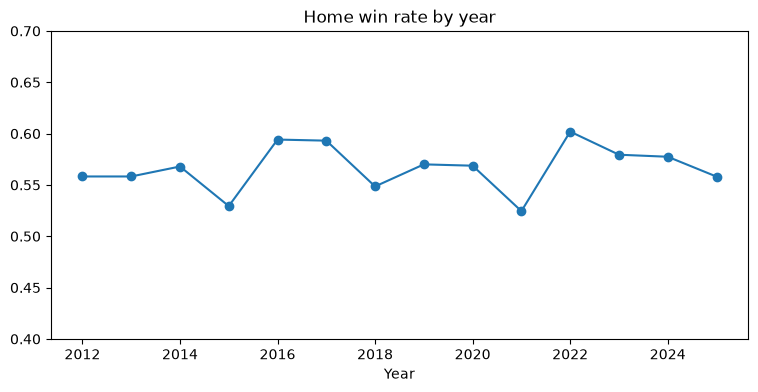

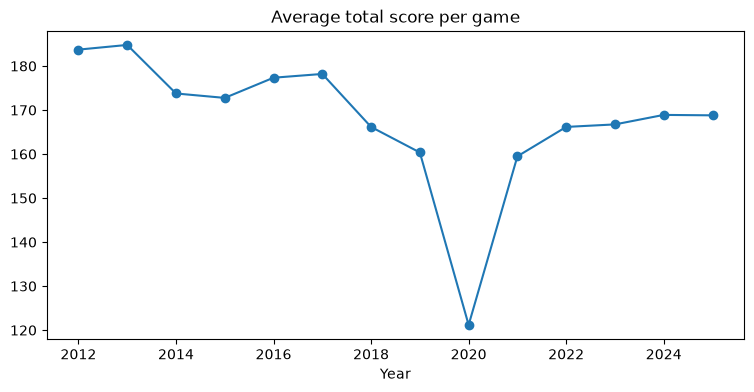

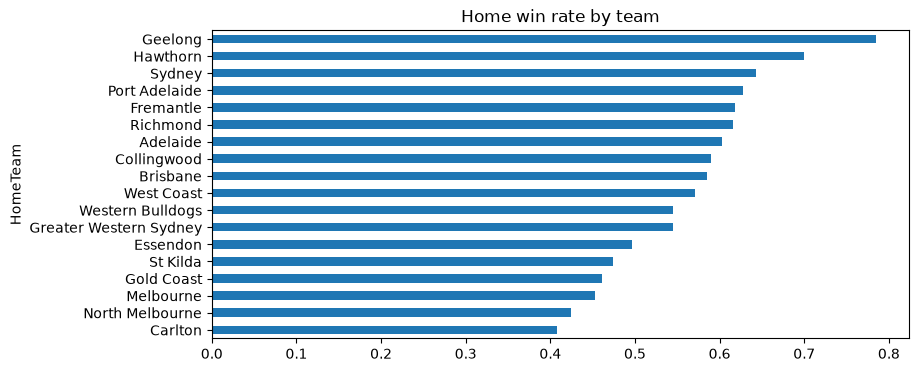

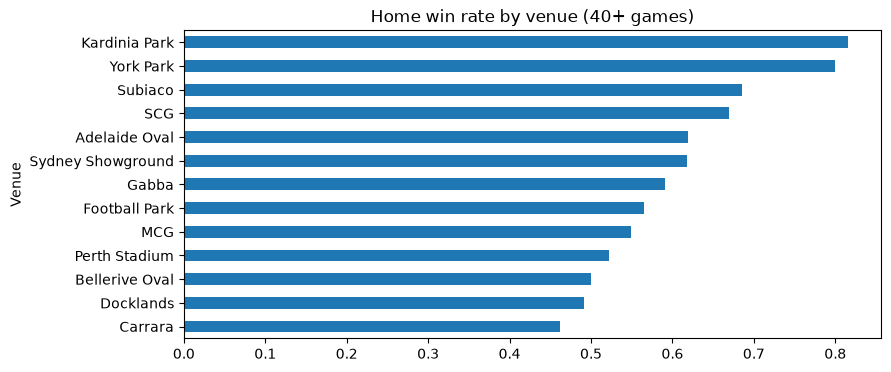

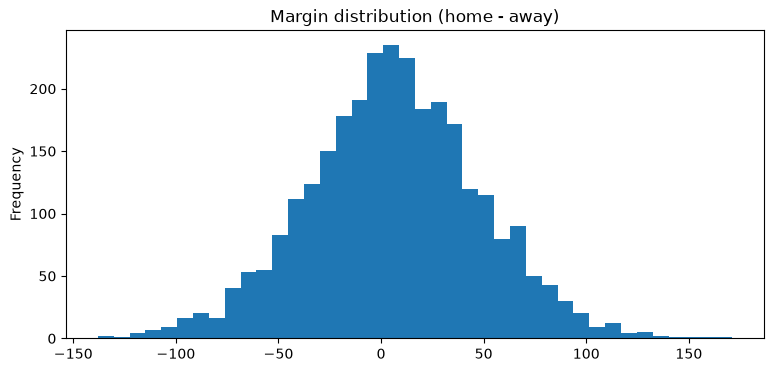

In [14]:
g = games[games["Margin"] != 0]
print("Home win rate:", round(g["HomeWin"].mean(), 3), "| draws:", (games["Margin"] == 0).sum())

g.groupby("Year")["HomeWin"].mean().plot(marker="o", title="Home win rate by year")
plt.ylim(0.4, 0.7); plt.show()

games.assign(Total=games["HomeTeamScore"] + games["AwayTeamScore"]) \
     .groupby("Year")["Total"].mean().plot(marker="o", title="Average total score per game")
plt.show()

g.groupby("HomeTeam")["HomeWin"].mean().sort_values().plot(kind="barh", title="Home win rate by team")
plt.show()

vc = g["Venue"].value_counts()
g[g["Venue"].isin(vc[vc >= 40].index)].groupby("Venue")["HomeWin"].mean() \
    .sort_values().plot(kind="barh", title="Home win rate by venue (40+ games)")
plt.show()

games["Margin"].plot(kind="hist", bins=40, title="Margin distribution (home - away)")
plt.show()

Top 10 by average Fantasy score (50+ games)
   PlayerName  Games  AvgFantasy
    Dane Swan     83       112.7
Harry Sheezel     67       106.0
  Dayne Beams    118       105.7
  Gary Ablett    143       104.2
 Tom Mitchell    206       104.0
 Zach Merrett    251       103.8
  Nick Daicos     93       102.1
 Tom Rockliff    167       102.1
 Matthew Boyd    107       101.6
Brent Stanton     93       101.5

Top 10 goalkickers 2012-2025
    PlayerName  Games  TotalGoals
Jeremy Cameron    279         734
   Tom Hawkins    277         679
Lance Franklin    210         610
 Jack Riewoldt    255         586
 Taylor Walker    253         586
  Josh Kennedy    202         573
  Jack Gunston    268         531
  Jack Darling    295         528
   Luke Breust    290         522
     Tom Lynch    223         473


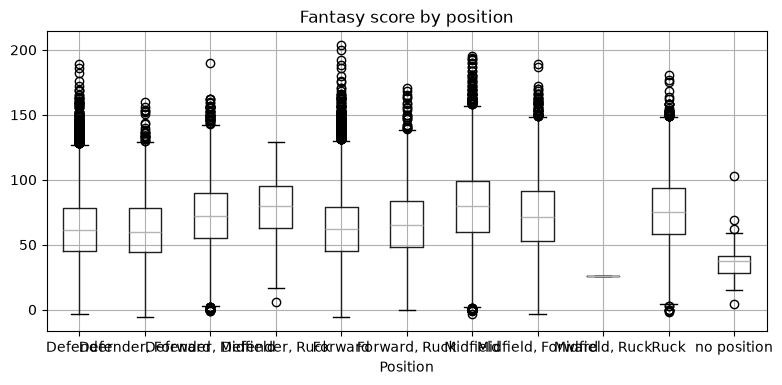

In [15]:
pg = stats.groupby(["PlayerId", "PlayerName"]).agg(
    Games=("GameKey", "size"), AvgFantasy=("Fantasy", "mean"),
    TotalGoals=("Goals", "sum"), AvgDisposals=("Disposals", "mean")).reset_index()

print("Top 10 by average Fantasy score (50+ games)")
print(pg[pg.Games >= 50].nlargest(10, "AvgFantasy")[["PlayerName", "Games", "AvgFantasy"]].round(1).to_string(index=False))

print("\nTop 10 goalkickers 2012-2025")
print(pg.nlargest(10, "TotalGoals")[["PlayerName", "Games", "TotalGoals"]].to_string(index=False))

sp = stats.merge(players[["PlayerId", "Position"]], on="PlayerId")
sp.boxplot(column="Fantasy", by="Position"); plt.suptitle(""); plt.title("Fantasy score by position")
plt.show()